# 01 — Data, baseline dan evaluasi Macro-F1

Revisi II. Model penelitian utama E42; baseline web historis CLIP-B32 dipisahkan. Seluruh tabel dihitung ulang dari input paket, tanpa training terselubung.

## Versi FULL — peta bukti

Seluruh berkas bukti yang sudah tersedia ditampilkan pada lampiran notebook ini, termasuk seluruh baris CSV dan semua gambar XAI. Status terbuka tetap memuat bukti yang tersedia serta pekerjaan tersisa.

[Indeks seluruh 28 revisi](../BUKTI_PER_REVISI/INDEX.html) · [Daftar cakupan lengkap](../documentation/NOTEBOOK_FULL_COVERAGE.json)

| Butir | Bagian | Status |
|---|---|---|
| R23 | [Agreement manusia dan riwayat korpus](#full-r23) | Berjalan |
| R24 | [Macro-F1 utama, akurasi/kappa pendamping](#full-r24) | Selesai |
| R28 | [Prediksi baseline/unimodal](#full-r28) | Selesai |
| R2 | [Codebook dan kelas penampung](#full-r2) | Selesai |
| R6 | [Adjudikasi dan eksklusi](#full-r6) | Berjalan |
| R8 | [Baseline dan ablasi](#full-r8) | Berjalan |
| R12 | [Macro-F1 sebagai metrik utama](#full-r12) | Selesai |

[Lampiran canonical lengkap](#full-lampiran)


## R18 — Identitas model utama yang dibekukan

**Model utama penelitian adalah E42 (`e42_tail_grid`, alias `M00_e42_baseline`): arsitektur Multi-Task Learning CLIP–IndoBERT dengan Joint Loss.** CLIP ViT-L/14 frozen mengekstraksi full/crop; IndoBERT memiliki 10 blok awal frozen dan 2 blok terakhir trainable. Fitur gabungan 2.304 dimensi masuk ke shared layer 256/ReLU/dropout0,3, lalu tiga head: isu10, domain7 dan entitas8.

Joint Loss adalah jumlah weighted cross entropy ketiga task, dibobot dan dinormalisasi dengan jumlah bobot task. Class weights dihitung hanya dari training. Bobot task tetap per run, bukan learned uncertainty Kendall. Detail formula dan konfigurasi lima fold tersedia langsung pada notebook02, bagian **R18 — Arsitektur Multi-Task Learning CLIP–IndoBERT dengan Joint Loss**.

Baseline CLIP-B32, varian backbone dan Qwen adalah pembanding. Demo web historis belum memakai E42. Penetapan E42 pada audit ini dinyatakan post-hoc; tidak mengubah protokol seleksi inner historis.


## Tujuan dan batas bukti
Macro-F1 utama, akurasi/kappa/precision/recall pendamping. Data manusia yang belum tersedia tetap Not Evaluated. Baca README dan PACKAGE_STATE untuk butir yang masih terbuka.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown, Code

# Reading saved outputs requires no setup. To Run all, first extract the ZIP.
locations = [Path.cwd(), *Path.cwd().parents, Path('/content/joy_revisi_ii')]
ROOT = next((p for p in locations if (p/'inputs/sources.json').is_file() and (p/'tools/evaluate.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Paket belum diekstrak. Ekstrak ZIP sehingga joy_revisi_ii/inputs dan joy_revisi_ii/tools tersedia, lalu buka notebook dari folder notebooks. Output tersimpan tetap dapat dibaca tanpa menjalankan sel.')
sys.path.insert(0, str(ROOT/'tools'))
import evaluate
verification = evaluate.run(ROOT, ROOT/'analysis', packaged=True)
B = pd.read_csv(ROOT/'analysis/metrics.csv')
P = pd.read_csv(ROOT/'analysis/paired_tests.csv')
TRACKER = pd.read_csv(ROOT/'documentation/REVISION_TRACKER_28.csv').fillna('')
print('Recomputed saved prediction analysis; no training, credential, Drive mount, API call, or invented human rating.')
print('Verified models:', verification['models'], '| bootstrap:', verification['bootstrap_resamples'])
def table(names):
    view = B[B.experiment.isin(names)]
    display(view[['experiment','phase','samples','task','macro_f1','macro_ci_low','macro_ci_high','accuracy','accuracy_ci_low','accuracy_ci_high','kappa','precision_macro','recall_macro']].style.format(precision=4))
    missing = sorted(set(names)-set(view.experiment))
    if missing:
        print('Not Evaluated / pending evidence:', ', '.join(missing))
def report(name):
    display(Markdown((ROOT/'documentation'/name).read_text()))
def plot(name):
    display(Image(filename=str(ROOT/'analysis'/name)))


evaluated BASELINE_CLIP_INDoBERT 740


evaluated e36_clip_l14 740


evaluated e37_token_pool 740


evaluated e38_l14_token 740


evaluated e39_feature_norm 740


evaluated e40_balanced_mmoe 740


... (71 outputs left out)

evaluated RII_TAIL_SINGLE_TASK 740


evaluated RII_TAIL_TEXT_SUPPORTING 740


evaluated RII_QWEN_QLORA_BASIC 740


Recomputed saved prediction analysis; no training, credential, Drive mount, API call, or invented human rating.
Verified models: 78 | bootstrap: 2000


In [2]:
data = pd.read_csv(ROOT/'inputs/DATASET_740_TASK2_DOMAIN.csv').fillna('')
print('Dataset:', len(data), 'unique IDs:', data.sample_id.nunique())
display(pd.concat([data[t].value_counts().rename_axis('label').reset_index(name='count').assign(task=t) for t in evaluate.TASKS], ignore_index=True))

Dataset: 740 unique IDs: 740


,label,count,task
0,corruption_and_bribery,160,task1_issue
1,power_and_governance,124,task1_issue
2,election_and_political_competition,112,task1_issue
3,economy_business_and_state_enterprise,81,task1_issue
4,public_policy_health_and_disaster,69,task1_issue
5,law_and_justice,53,task1_issue
6,human_rights_and_social_conflict,52,task1_issue
7,environment_and_natural_resources,39,task1_issue
8,security_defense_and_terrorism,36,task1_issue
9,other_issue,14,task1_issue


## Metode evaluasi dan pelaporan
Seluruh kelas canonical tetap berada dalam denominator Macro-F1. Akurasi identik dengan Micro-F1 pada tugas single-label ini. CI bootstrap bersyarat pada prediksi yang tersimpan dan tidak menghapus bias seleksi.

In [3]:
report('STATISTICAL_METHOD.md')

# Metode evaluasi dan statistik

Metrik utama Macro-F1 dengan codebook label tetap (zero_division=0), disajikan per task. Rerata tiga Macro-F1 berbobot sama hanya ringkasan; minimum diagnostik. Akurasi, macro-precision/recall, Cohen kappa dan metrik per kelas disertakan. Micro-F1 single-label identik dengan akurasi dan tidak dipakai untuk memberi kesan metrik berbeda.

CI akurasi: Wilson 95%. CI Macro-F1: percentile bootstrap 2000 replikasi atas pasangan gold/prediksi, seed20261101+indeks task. Selisih macro memakai bootstrap berpasangan atas triple gold/before/after. Implementasi multinomial histogram joint ekuivalen terhadap resampling IID pengamatan, dengan kelas yang tidak muncul di replikasi tetap berada pada denominator macro.

McNemar exact dua sisi menguji selisih benar/salah, yaitu akurasi, bukan Macro-F1. Holm diterapkan ke seluruh pasangan-task yang dicantumkan dalam satu keluarga. Pasangan di keluarga baru ditetapkan dalam source evaluator sebelum tabel baru dihasilkan. CI bootstrap selisih bersifat pointwise eksploratif; jangan menganggapnya sudah terkoreksi family-wise. Tidak signifikan bukan bukti kesetaraan, dan besar selisih tidak boleh diberi p hanya dari jumlah sampel benar yang tidak berpasangan.

Seluruh inference bersyarat pada prediksi OOF tersimpan: overlap data training lintasfold, adaptive selection pada korpus sama, annotator uncertainty dan variability seed baru belum seluruhnya tercakup. Tidak ada holdout baru yang diklaim dari fold yang pernah dipakai seleksi. Kriteria keberhasilan adalah perbandingan yang terukur terhadap majority/unimodal/single-task, bukan angka0,70 tunggal. Target proposal historis tetap disebut sebagai target lama yang belum tercapai, bukan dihapus dari sejarah.

Sumber metode: [SciPy binomtest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html), [SciPy paired bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html), [Dietterich1998](https://doi.org/10.1162/089976698300017197).


## Baseline, majority dan model utama

In [4]:
table(['MAJORITY_TRAIN_FOLD','BASELINE_CLIP_INDoBERT','e42_tail_grid'])

,experiment,phase,samples,task,macro_f1,macro_ci_low,macro_ci_high,accuracy,accuracy_ci_low,accuracy_ci_high,kappa,precision_macro,recall_macro
0,BASELINE_CLIP_INDoBERT,historical_740_oof,740,task1_issue,0.4380,0.3957,0.4749,0.4554,0.4198,0.4914,0.3811,0.4256,0.4733
1,BASELINE_CLIP_INDoBERT,historical_740_oof,740,task2_domain_sumber,0.3197,0.2871,0.3511,0.3203,0.2877,0.3547,0.2067,0.3189,0.3407
2,BASELINE_CLIP_INDoBERT,historical_740_oof,740,task3_primary_entity_type,0.2764,0.2423,0.3103,0.3554,0.3217,0.3906,0.2157,0.2711,0.3176
24,e42_tail_grid,historical_740_oof,740,task1_issue,0.5255,0.4810,0.5647,0.5541,0.5181,0.5895,0.4853,0.5277,0.5258
25,e42_tail_grid,historical_740_oof,740,task2_domain_sumber,0.3956,0.3606,0.4295,0.4351,0.3998,0.4711,0.3154,0.3973,0.3953
26,e42_tail_grid,historical_740_oof,740,task3_primary_entity_type,0.4034,0.3555,0.4469,0.5189,0.4829,0.5547,0.3537,0.4188,0.3956
153,MAJORITY_TRAIN_FOLD,fold_training_majority,740,task1_issue,0.0356,0.0314,0.0395,0.2162,0.1881,0.2473,0.0000,0.0216,0.1000
154,MAJORITY_TRAIN_FOLD,fold_training_majority,740,task2_domain_sumber,0.0641,0.0581,0.0695,0.2892,0.2577,0.3229,0.0000,0.0413,0.1429
155,MAJORITY_TRAIN_FOLD,fold_training_majority,740,task3_primary_entity_type,0.0746,0.0702,0.0789,0.4257,0.3905,0.4616,0.0000,0.0532,0.1250


In [5]:
display(pd.read_csv(ROOT/'analysis/per_class.csv').query("experiment in ['BASELINE_CLIP_INDoBERT','e42_tail_grid']").style.format(precision=4))

,experiment,task,label,precision,recall,f1,support,predicted
0,BASELINE_CLIP_INDoBERT,task1_issue,corruption_and_bribery,0.6262,0.4188,0.5019,160,107
1,BASELINE_CLIP_INDoBERT,task1_issue,economy_business_and_state_enterprise,0.4691,0.4691,0.4691,81,81
2,BASELINE_CLIP_INDoBERT,task1_issue,election_and_political_competition,0.5159,0.5804,0.5462,112,126
3,BASELINE_CLIP_INDoBERT,task1_issue,environment_and_natural_resources,0.4151,0.5641,0.4783,39,53
4,BASELINE_CLIP_INDoBERT,task1_issue,human_rights_and_social_conflict,0.4000,0.3462,0.3711,52,45
5,BASELINE_CLIP_INDoBERT,task1_issue,law_and_justice,0.3333,0.4717,0.3906,53,75
6,BASELINE_CLIP_INDoBERT,task1_issue,other_issue,0.2857,0.5714,0.3810,14,28
7,BASELINE_CLIP_INDoBERT,task1_issue,power_and_governance,0.4149,0.3145,0.3578,124,94
8,BASELINE_CLIP_INDoBERT,task1_issue,public_policy_health_and_disaster,0.4762,0.5797,0.5229,69,84
9,BASELINE_CLIP_INDoBERT,task1_issue,security_defense_and_terrorism,0.3191,0.4167,0.3614,36,47


## Pemulihan prediksi mentah
Kontrol baseline weighted mereplay seluruh 740 prediksi baseline secara identik. Image-only/text-only kini mempunyai prediksi mentah untuk statistik berpasangan.

In [6]:
report('HISTORICAL_REPLAY.md')
table(['RII_FROZEN_MTL_WEIGHTED','RII_FROZEN_MTL_UNWEIGHTED','RII_FROZEN_IMAGE_ONLY','RII_FROZEN_TEXT_SUPPORTING','RII_FROZEN_TEXT_HEADLINE'])

# Pemulihan prediksi baseline

RII_FROZEN_MTL_WEIGHTED mereplikasi120 epoch full-batch, seed42, shared256/ReLU/dropout0.4, AdamW1e-3/wd1e-4, class weights training-only, CLIP-B32+IndoBERT CLS beku, dan lima fold yang sama. Prediksi ketiga task identik terhadap kolom baseline E42 pada seluruh740 sampel (0perbedaan). Image-only dan text-only juga menghasilkan metrik historis yang sama, kini dengan prediksi mentah lengkap. Single-task/tanpa weighting/headline-only/rich128 adalah kontrol baru yang diberi nama terpisah, bukan angka historis yang ditulis ulang. Text-only supporting sebenarnya sudah ada pada extractor lama; headline-only ditambahkan sebagai kontras input yang jelas.

Keluarga ini adalah ablation baseline CLIP-B32 beku, bukan ablasi E42 yang memiliki CLIP-L14 dan tail teks trainable. Ablasi E42-family baru berada pada RII_TAIL_*. Semua sumber/seed/fold/OOF dipertahankan.


,experiment,phase,samples,task,macro_f1,macro_ci_low,macro_ci_high,accuracy,accuracy_ci_low,accuracy_ci_high,kappa,precision_macro,recall_macro
180,RII_FROZEN_IMAGE_ONLY,revision_ii_new_740_oof,740,task1_issue,0.2633,0.2275,0.2958,0.2716,0.2408,0.3048,0.1796,0.2582,0.2942
181,RII_FROZEN_IMAGE_ONLY,revision_ii_new_740_oof,740,task2_domain_sumber,0.3038,0.2701,0.3370,0.3095,0.2772,0.3437,0.1904,0.3057,0.3165
182,RII_FROZEN_IMAGE_ONLY,revision_ii_new_740_oof,740,task3_primary_entity_type,0.2390,0.2066,0.2704,0.3338,0.3007,0.3685,0.1840,0.2403,0.2639
189,RII_FROZEN_MTL_UNWEIGHTED,revision_ii_new_740_oof,740,task1_issue,0.2597,0.2338,0.2839,0.4216,0.3865,0.4575,0.3024,0.2612,0.2785
190,RII_FROZEN_MTL_UNWEIGHTED,revision_ii_new_740_oof,740,task2_domain_sumber,0.2239,0.1980,0.2496,0.3676,0.3336,0.4029,0.1653,0.3462,0.2605
191,RII_FROZEN_MTL_UNWEIGHTED,revision_ii_new_740_oof,740,task3_primary_entity_type,0.1687,0.1473,0.1903,0.4730,0.4372,0.5090,0.1753,0.2022,0.1873
192,RII_FROZEN_MTL_WEIGHTED,revision_ii_new_740_oof,740,task1_issue,0.4380,0.3957,0.4749,0.4554,0.4198,0.4914,0.3811,0.4256,0.4733
193,RII_FROZEN_MTL_WEIGHTED,revision_ii_new_740_oof,740,task2_domain_sumber,0.3197,0.2871,0.3511,0.3203,0.2877,0.3547,0.2067,0.3189,0.3407
194,RII_FROZEN_MTL_WEIGHTED,revision_ii_new_740_oof,740,task3_primary_entity_type,0.2764,0.2423,0.3103,0.3554,0.3217,0.3906,0.2157,0.2711,0.3176
198,RII_FROZEN_TEXT_HEADLINE,revision_ii_new_740_oof,740,task1_issue,0.2729,0.2389,0.3038,0.2986,0.2668,0.3326,0.2148,0.2769,0.3101


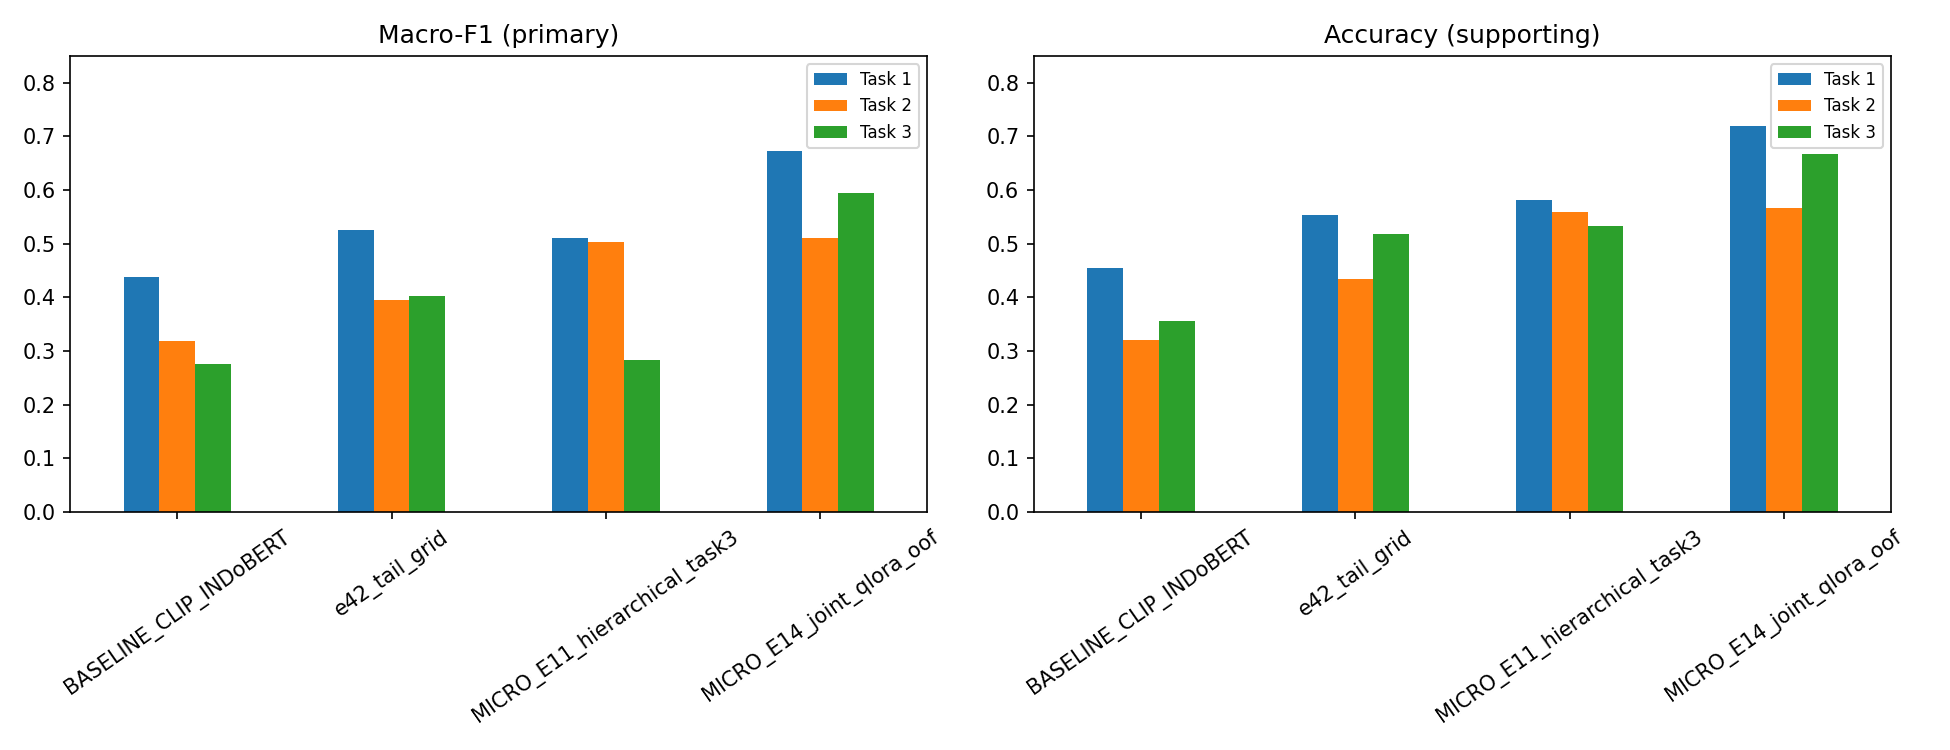

In [7]:
plot('primary_results.png')

## Anotasi, codebook dan korpus

In [8]:
report('CORPUS_HISTORY.md')
report('CODEBOOK_REVISI.md')

# Riwayat korpus dan anotasi

Dataset canonical yang ditemukan: 740 ID unik, SHA-256 `cba20f8250bcb59481ed2d3d7d5d42fb8242c96a7ba2d11a2cd02ad80862961a`. Eligibility: {'eligible_sociopolitical': 740}. Tidak ditemukan korpus awal 1.040 baris atau log 300 keputusan eksklusi per ID. Kolom `annotator_confidence`, deskripsi dan mapping note adalah satu set anotasi yang sudah tergabung; tidak tersedia dua set label independen untuk menghitung kappa manusia. Jangan menganggap ketiadaan data awal membuktikan sampel sengketa dibuang. Alasan umum penyusutan telah diklarifikasi; dokumentasi rinci per ID dan analisis sensitivitas belum dapat direkonstruksi.

Tindakan siap pakai: paket dua anotator untuk 150 sampul acak, serta audit 60 kasus kelas penampung. Kappa tidak dihitung dari prediksi AI sebagai pengganti manusia. Setelah anotasi nyata tersedia, jalankan `human_agreement.py`.

## Klarifikasi dari Joy — diterima 2 November 2026

Menurut keterangan Joy yang diteruskan pengguna, jumlah korpus berkurang karena banyak citra sampul Tempo berkualitas buruk dan tidak dapat dilabeli. Joy menyatakan alasan ini telah disampaikan sebelumnya. Dengan demikian, **alasan umum penyusutan sudah dijelaskan** dan tidak lagi dicatat sebagai alasan yang belum diberikan.

Pesan menggunakan angka sekitar 1.000 dan 700-an. Angka spesifik 1.040 bersumber dari dokumen revisi/proposal; jumlah 740 ID unik dapat diperiksa pada dataset canonical. Pesan ini tidak memberikan tanggal komunikasi sebelumnya, daftar gambar yang dikeluarkan, kriteria teknis terukur, atau keputusan per ID; rincian tersebut tidak direka.

Kualitas citra buruk berbeda dari sengketa label atau ketidakpastian interpretasi semantik. Tidak ada kesimpulan bahwa sampel sengketa sengaja dibuang untuk meningkatkan metrik. Bila dokumentasi seleksi asli masih tersedia, gunakan untuk melengkapi keterlacakan; ketidaktersediaannya tidak meniadakan penjelasan Joy.

Bagian R23 tentang **kesepakatan antaranotator** tetap terpisah: kappa memerlukan dua set label manusia independen. Penjelasan penyusutan tidak menggantikan data agreement tersebut. Catatan sumber: R23_KLARIFIKASI_JOY.json.


# Codebook operasional dan adjudikasi

Label canonical tetap. Tidak ada relabeling otomatis berdasarkan kesalahan model. Definisi tiga task dan daftar label bersumber dari source/protokol yang disertakan. Task 1: isu utama paling dominan; Task 2: domain sumber pemetaan metaforis, berbeda dari isu sasaran; Task 3: tipe entitas yang menjadi fokus kritik, bukan setiap objek yang tampak.

Kelas penampung harus dipakai dengan alasan tertulis. `other_issue`: isu dapat diidentifikasi tetapi berada di luar sembilan kategori utama. `LAINNYA`: ada pemetaan metaforis yang dapat dijelaskan, tetapi sumber tidak termasuk lima domain positif; jangan dipakai hanya karena penilai ragu. `NON_METAFORA`: tidak ditemukan pemetaan sumber–sasaran yang dapat dipertanggungjawabkan; berbeda dari metafora yang sumbernya di luar taxonomy. `multiple_or_other`: catat terpisah alasan “beberapa sasaran dominan” atau “tipe tidak tercakup”, bukan menyatukan semua ketidakpastian.

Prosedur: dua anotator menilai independen, menyimpan label/tingkat keyakinan/alasan; kappa dihitung sebelum diskusi; adjudikator menulis keputusan dan alasan di file baru. Sampel sengketa tidak dihapus hanya untuk menaikkan metrik. Pemecahan kelas memerlukan dataset/codebook versi baru dan tabel pemetaan; hasil lama tetap dipertahankan.

Audit 60 contoh disiapkan untuk memastikan apakah ada subgroup koheren. Belum ada keputusan manusia yang dapat dijadikan dasar perubahan gold. Template anotasi150 tidak memuat gold/model prediction. Daftar kategori yang diperbolehkan ada di protocol.json.

Definisi seluruh label sesuai taxonomy yang dipakai, tanpa perubahan gold:

### task1_issue

| label | definition |
| --- | --- |
| corruption_and_bribery | korupsi, suap, gratifikasi, atau penyalahgunaan dana dan jabatan |
| economy_business_and_state_enterprise | ekonomi, bisnis, keuangan, perusahaan, BUMN, pajak, atau perdagangan |
| election_and_political_competition | pemilu, pilkada, kampanye, koalisi, kandidat, atau kompetisi politik |
| environment_and_natural_resources | lingkungan, energi, tambang, hutan, lahan, air, atau sumber daya alam |
| human_rights_and_social_conflict | hak asasi, diskriminasi, kekerasan sosial, buruh, agama, atau konflik masyarakat |
| law_and_justice | hukum, pengadilan, polisi, kejaksaan, penyidikan, atau keadilan |
| other_issue | isu utama di luar sembilan kategori lain |
| power_and_governance | kekuasaan, pemerintahan, kabinet, birokrasi, kebijakan, atau kepemimpinan |
| public_policy_health_and_disaster | kesehatan, pendidikan, layanan publik, bencana, pandemi, atau kebijakan sosial |
| security_defense_and_terrorism | militer, pertahanan, keamanan nasional, intelijen, terorisme, atau perang |

### task2_domain_sumber

| label | definition |
| --- | --- |
| BENCANA_JERAT | ancaman, bencana, perangkap, jerat, tekanan, atau keadaan terjepit sebagai kiasan |
| HEWAN_TUBUH | hewan, anatomi, penyakit, deformasi, atau perilaku biologis sebagai kiasan |
| KONSUMSI_TRANSAKSI | makanan, jamuan, selera, jual-beli, uang, atau pertukaran nilai sebagai kiasan |
| LAINNYA | metafora dengan domain sumber selain lima domain metaforis yang disebut |
| MESIN_INFRASTRUKTUR | mesin, alat, kendaraan, bangunan, wadah, atau mekanisme buatan sebagai kiasan |
| NON_METAFORA | adegan literal tanpa pemetaan metaforis |
| PERMAINAN_KONTES | permainan, pertandingan, kompetisi, pertunjukan, atau seni sebagai kiasan |

### task3_primary_entity_type

| label | definition |
| --- | --- |
| business | perusahaan swasta, pengusaha, atau organisasi bisnis |
| civil_society_or_media | warga, aktivis, organisasi sipil, media, jurnalis, atau kelompok masyarakat |
| government | pemerintah, presiden sebagai institusi eksekutif, menteri, kabinet, birokrasi, atau lembaga negara umum |
| individual | satu orang tertentu sebagai sasaran utama |
| judiciary_or_law_enforcement | polisi, jaksa, hakim, pengadilan, KPK, atau lembaga penegak hukum |
| legislature | DPR, parlemen, legislator, atau lembaga legislatif |
| multiple_or_other | beberapa tipe sasaran sekaligus atau sasaran yang tidak termasuk kategori lain |
| political_party | partai politik atau organisasi politik partisan |

Jika beberapa isu/sasaran sama dominannya, anotator menuliskan pilihan dan alasan untuk adjudikasi; jangan menyamakan ketidakpastian dengan NON_METAFORA atau membuang kasus sengketa. Bedakan kritik orang tertentu (`individual`) dari institusi eksekutif (`government`) berdasarkan fokus kritik, bukan semata-mata ada gambar manusia.

Definisi sumber Task 2 yang digunakan pada generator historis (sebagai bukti prompt, bukan hasil adjudikasi baru):

```text
Ini sampul Majalah Tempo.
Judul utama: {judul}
Teks pendukung: {pendukung}

Tentukan domain sumber metafora visual-verbal sampul ini, yaitu dari ranah apa kiasan gambarnya diambil (bukan isu yang dibahas). Pilih tepat satu kode:
MESIN_INFRASTRUKTUR: Domain sumber berupa mesin, alat kerja, kendaraan, bangunan, infrastruktur, atau mekanisme buatan. Kriteria: ada pemetaan dari fungsi, kerusakan, pengendalian, atau kerja alat/struktur ke isu sasaran. Pembeda: alat yang tampil literal tidak otomatis metafora; alat transaksi/permainan dipilah menurut mekanisme pemetaan dominan.
PERMAINAN_KONTES: Domain sumber berupa permainan, pertandingan, kompetisi, atau panggung pertunjukan sebagai arena berstrategi. Kriteria: pemetaan memakai menang-kalah, aturan main, pemain, peran, panggung, atau pengaturan pertunjukan. Pembeda: persaingan politik literal bukan metafora; perlu sumber metaforis.
BENCANA_JERAT: Domain sumber berupa bencana, ancaman, jerat, perangkap, atau keadaan fisik terjepit. Kriteria: pemetaan memakai bahaya, kehancuran, terperangkap, atau tekanan ruang sebagai sumber makna. Pembeda: bencana aktual tanpa pemetaan dapat NON_METAFORA; bagian tubuh dalam jerat dipilah menurut mekanisme dominan.
HEWAN_TUBUH: Domain sumber berupa hewan, bagian tubuh, atau bentuk dan perilaku biologis. Kriteria: sifat hewan, anatomi, deformasi, atau perilaku tubuh dipetakan ke tokoh atau persoalan. Pembeda: potret manusia atau hewan literal tidak cukup; jika konsumsi tumpang tindih, pilih mekanisme dominan.
KONSUMSI_TRANSAKSI: Domain sumber berupa makanan, jamuan, selera, jual-beli, pembayaran, atau pertukaran keuntungan. Kriteria: ada pemetaan dari makan, memilih hidangan, berbagi jatah, atau pertukaran nilai ke persoalan sasaran. Pembeda: makanan atau uang literal tidak otomatis metafora; jika hewan merupakan sumber utama, pertimbangkan HEWAN_TUBUH.
NON_METAFORA: Sampul tanpa pemetaan metaforis visual-verbal. Kriteria: elemen dipahami secara literal dan tidak ada hubungan sumber-sasaran metaforis yang cukup. Pembeda: ketidakpastian pembaca bukan bukti tanpa metafora.
LAINNYA: Domain sumber metafora yang tidak tercakup lima domain positif lainnya. Kriteria: metafora teridentifikasi tetapi mekanisme sumbernya tidak cocok dengan kategori yang tersedia. Pembeda: berbeda dari NON_METAFORA karena tetap ada pemetaan metaforis; jangan dipakai sebagai tempat semua kasus ambigu.

Jawab hanya dengan JSON satu baris: {"sumber_visual": "<benda/adegan yang menjadi sumber kiasan>", "domain": "<KODE>", "alasan": "<satu kalimat>"}
```


## Kesimpulan
Baseline lama dan E42 adalah dua model berbeda. Kinerja rendah/tinggi dilaporkan per task, bersama ketidakpastiannya. Anotasi ganda dan riwayat eksklusi masih memerlukan bukti manusia; keduanya tidak disimpulkan dari nama file atau keyakinan anotator tunggal.

## Screenshot delivery sebelumnya dan perubahan sekarang

Gambar berikut disalin utuh dari bukti delivery **20 Oktober 2026**. Ini catatan versi sebelumnya; hasil terbaru ada di tabel dan output notebook ini. Screenshot historis tidak menjadi bukti kelulusan Colab atau deployment E42. Sumber/hash tersedia di `screenshots/EVIDENCE_MANIFEST.json`.

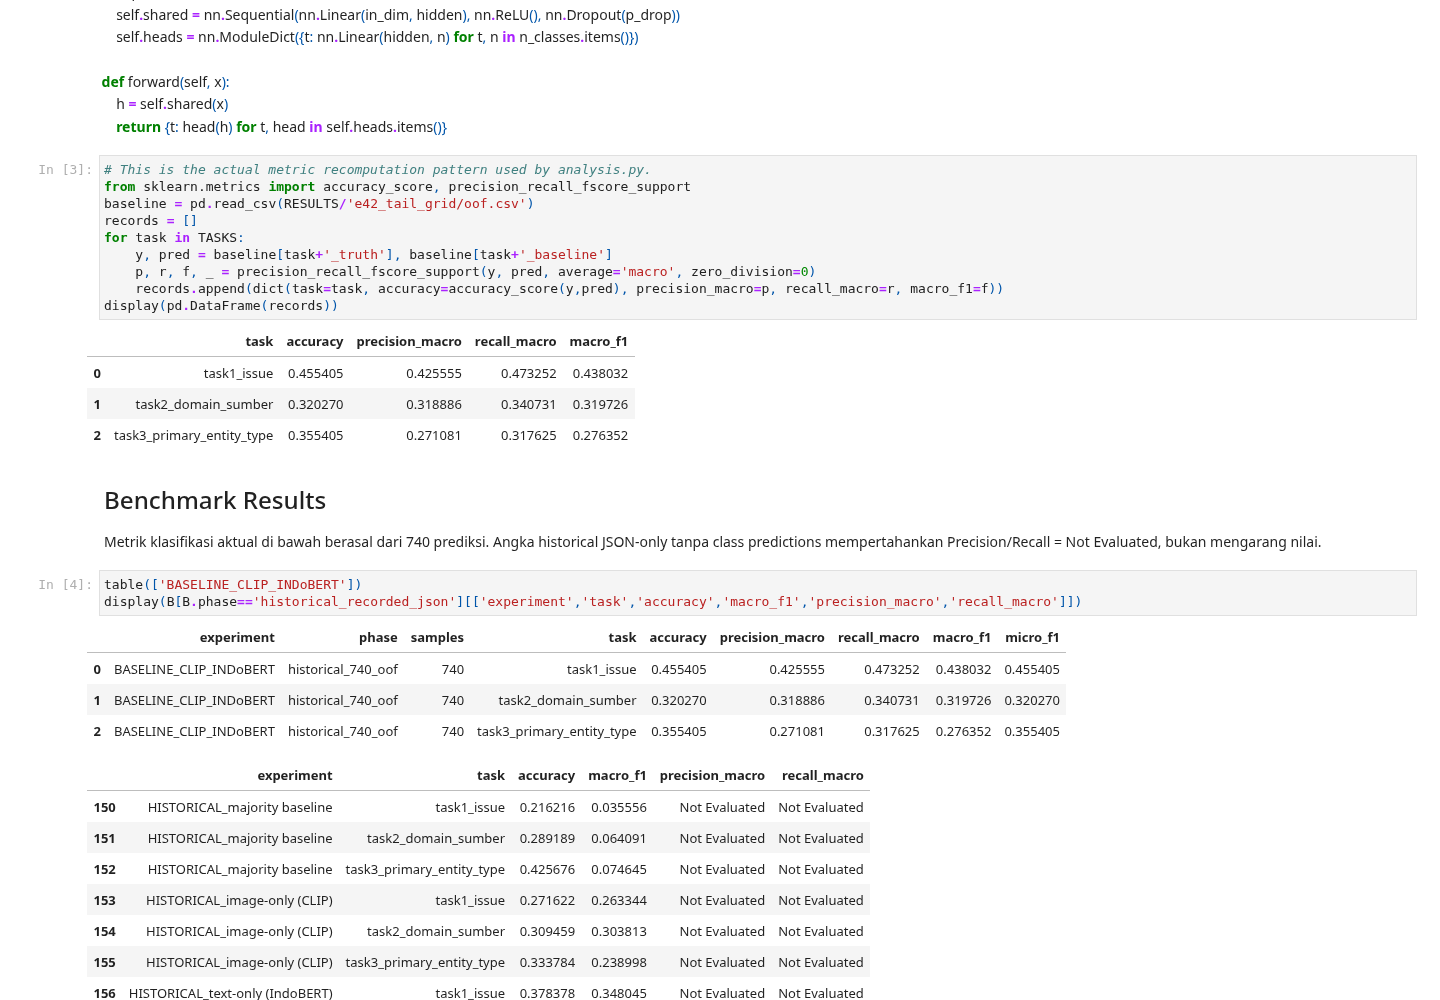

Screenshot historis 01_baseline — delivery 20 Oktober 2026.

## Lampiran FULL — bukti per revisi

File asli tetap disertakan. Tabel besar dapat digulir; JSON dan source lengkap dapat dibuka melalui panel. Gambar historis diberi tanggal pada nama/sumbernya.

In [9]:
from notebook_evidence import render_group

<a id="full-r23"></a>

## R23 — Agreement manusia dan riwayat korpus

**Status: Berjalan.**

**Yang belum selesai:** Alasan umum eksklusi sudah diklarifikasi Joy: kualitas citra buruk sehingga tidak dapat dilabeli, dan menurut Joy pernah disampaikan. Yang belum tersedia: dua set anotasi independen untuk kappa; dokumentasi korpus awal/keputusan per ID dan sensitivitas belum dapat direkonstruksi.

**Penanggung jawab:** Dua anotator; pemilik data untuk dokumentasi rinci bila tersedia

Bukti/instrumen yang sudah tersedia:

- [documentation/CORPUS_HISTORY.md](../documentation/CORPUS_HISTORY.md)
- [documentation/HUMAN_EVIDENCE_SEARCH.json](../documentation/HUMAN_EVIDENCE_SEARCH.json)
- [human_inputs/annotation](../human_inputs/annotation)

Instrumen kosong bukan hasil penilaian manusia. Materi analisis/provenance yang tersedia ditampilkan pada bagian utama atau lampiran canonical.


<a id="full-r24"></a>

## R24 — Macro-F1 utama, akurasi/kappa pendamping

**Status: Selesai.**

Permintaan bukti: Bukti yang diserahkan. Seluruh tabel hasil dalam versi macro, dan berkas results.py yang sudah direvisi.

[Navigasi bukti R24](../BUKTI_PER_REVISI/R24/BUKA_BUKTI.html)



In [10]:
render_group(ROOT, 'R24', '01_baseline.ipynb')

experiment,task,samples,correct,accuracy,precision_macro,recall_macro,macro_f1,kappa,accuracy_ci_low,accuracy_ci_high,macro_ci_low,macro_ci_high,phase,source,source_sha256
BASELINE_CLIP_INDoBERT,task1_issue,740,337,0.455405,0.425555,0.473252,0.438032,0.381144,0.419846,0.491425,0.395651,0.474939,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e42_tail_grid/oof.csv,bc4c55291463106d398cf90c9f796724f7f22595d92668bda324a51e9799b642
BASELINE_CLIP_INDoBERT,task2_domain_sumber,740,237,0.320270,0.318886,0.340731,0.319726,0.206682,0.287656,0.354741,0.287114,0.351068,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e42_tail_grid/oof.csv,bc4c55291463106d398cf90c9f796724f7f22595d92668bda324a51e9799b642
BASELINE_CLIP_INDoBERT,task3_primary_entity_type,740,263,0.355405,0.271081,0.317625,0.276352,0.215741,0.321748,0.390557,0.242286,0.310296,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e42_tail_grid/oof.csv,bc4c55291463106d398cf90c9f796724f7f22595d92668bda324a51e9799b642
e36_clip_l14,task1_issue,740,331,0.447297,0.412416,0.427837,0.417758,0.366568,0.411837,0.483302,0.374039,0.457756,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e36_clip_l14/oof.csv,ca563ec0843e302bd3a79648cdc860a6d4b173c46907e77eaebc77b442135513
e36_clip_l14,task2_domain_sumber,740,337,0.455405,0.428986,0.434894,0.431522,0.347224,0.419846,0.491425,0.393045,0.464722,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e36_clip_l14/oof.csv,ca563ec0843e302bd3a79648cdc860a6d4b173c46907e77eaebc77b442135513
e36_clip_l14,task3_primary_entity_type,740,343,0.463514,0.334485,0.365580,0.345496,0.313896,0.427866,0.499538,0.307800,0.381175,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e36_clip_l14/oof.csv,ca563ec0843e302bd3a79648cdc860a6d4b173c46907e77eaebc77b442135513
e37_token_pool,task1_issue,740,384,0.518919,0.474561,0.505830,0.485113,0.450224,0.482915,0.554727,0.443785,0.522769,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e37_token_pool/oof.csv,ec3acbd18ea4b297150062eec3a3a1e56b10cc4bc56109c71db15c0635bf8160
e37_token_pool,task2_domain_sumber,740,283,0.382432,0.368348,0.373811,0.369245,0.265144,0.348110,0.417969,0.336062,0.403836,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e37_token_pool/oof.csv,ec3acbd18ea4b297150062eec3a3a1e56b10cc4bc56109c71db15c0635bf8160
e37_token_pool,task3_primary_entity_type,740,318,0.429730,0.334769,0.370440,0.344326,0.280974,0.394516,0.465670,0.301962,0.384679,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e37_token_pool/oof.csv,ec3acbd18ea4b297150062eec3a3a1e56b10cc4bc56109c71db15c0635bf8160
e38_l14_token,task1_issue,740,375,0.506757,0.472562,0.503878,0.483509,0.435455,0.470793,0.542650,0.438980,0.523423,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e38_l14_token/oof.csv,a5a4ea0ec833773ab2f0f444941e561491855e7aec99fd6abdaff01c95f642ef


experiment,task,label,precision,recall,f1,support,predicted
BASELINE_CLIP_INDoBERT,task1_issue,corruption_and_bribery,0.626168,0.418750,0.501873,160,107
BASELINE_CLIP_INDoBERT,task1_issue,economy_business_and_state_enterprise,0.469136,0.469136,0.469136,81,81
BASELINE_CLIP_INDoBERT,task1_issue,election_and_political_competition,0.515873,0.580357,0.546218,112,126
BASELINE_CLIP_INDoBERT,task1_issue,environment_and_natural_resources,0.415094,0.564103,0.478261,39,53
BASELINE_CLIP_INDoBERT,task1_issue,human_rights_and_social_conflict,0.400000,0.346154,0.371134,52,45
BASELINE_CLIP_INDoBERT,task1_issue,law_and_justice,0.333333,0.471698,0.390625,53,75
BASELINE_CLIP_INDoBERT,task1_issue,other_issue,0.285714,0.571429,0.380952,14,28
BASELINE_CLIP_INDoBERT,task1_issue,power_and_governance,0.414894,0.314516,0.357798,124,94
BASELINE_CLIP_INDoBERT,task1_issue,public_policy_health_and_disaster,0.476190,0.579710,0.522876,69,84
BASELINE_CLIP_INDoBERT,task1_issue,security_defense_and_terrorism,0.319149,0.416667,0.361446,36,47


<a id="full-r28"></a>

## R28 — Prediksi baseline/unimodal

**Status: Selesai.**

Permintaan bukti: Bukti yang diserahkan. Empat berkas predictions.csv untuk ablasi unimodal, dan tabel uji McNemar multimodal versus unimodal.

[Navigasi bukti R28](../BUKTI_PER_REVISI/R28/BUKA_BUKTI.html)



In [11]:
render_group(ROOT, 'R28', '01_baseline.ipynb')

sample_id,fold,task1_issue_truth,task1_issue_pred,task2_domain_sumber_truth,task2_domain_sumber_pred,task3_primary_entity_type_truth,task3_primary_entity_type_pred
TMP-00E55D6B8B93,5,security_defense_and_terrorism,corruption_and_bribery,MESIN_INFRASTRUKTUR,MESIN_INFRASTRUKTUR,government,individual
TMP-01279CEA7FCE,2,corruption_and_bribery,corruption_and_bribery,MESIN_INFRASTRUKTUR,MESIN_INFRASTRUKTUR,individual,individual
TMP-015F9748262A,2,public_policy_health_and_disaster,corruption_and_bribery,HEWAN_TUBUH,MESIN_INFRASTRUKTUR,multiple_or_other,individual
TMP-016B39956ABA,5,public_policy_health_and_disaster,corruption_and_bribery,NON_METAFORA,MESIN_INFRASTRUKTUR,civil_society_or_media,individual
TMP-0204848C7A5C,1,security_defense_and_terrorism,corruption_and_bribery,MESIN_INFRASTRUKTUR,MESIN_INFRASTRUKTUR,individual,individual
TMP-02BB4CA168D5,1,power_and_governance,corruption_and_bribery,PERMAINAN_KONTES,MESIN_INFRASTRUKTUR,individual,individual
TMP-02FBDB1CF070,2,corruption_and_bribery,corruption_and_bribery,KONSUMSI_TRANSAKSI,MESIN_INFRASTRUKTUR,multiple_or_other,individual
TMP-03083B8A31BF,3,environment_and_natural_resources,corruption_and_bribery,HEWAN_TUBUH,MESIN_INFRASTRUKTUR,civil_society_or_media,individual
TMP-0353B4BD8BEC,1,power_and_governance,corruption_and_bribery,PERMAINAN_KONTES,MESIN_INFRASTRUKTUR,individual,individual
TMP-03BF269E287C,5,election_and_political_competition,corruption_and_bribery,PERMAINAN_KONTES,MESIN_INFRASTRUKTUR,individual,individual


sample_id,fold,task1_issue_truth,task1_issue_pred,task2_domain_sumber_truth,task2_domain_sumber_pred,task3_primary_entity_type_truth,task3_primary_entity_type_pred
TMP-00E55D6B8B93,5,security_defense_and_terrorism,public_policy_health_and_disaster,MESIN_INFRASTRUKTUR,KONSUMSI_TRANSAKSI,government,government
TMP-01279CEA7FCE,2,corruption_and_bribery,economy_business_and_state_enterprise,MESIN_INFRASTRUKTUR,PERMAINAN_KONTES,individual,business
TMP-015F9748262A,2,public_policy_health_and_disaster,public_policy_health_and_disaster,HEWAN_TUBUH,BENCANA_JERAT,multiple_or_other,judiciary_or_law_enforcement
TMP-016B39956ABA,5,public_policy_health_and_disaster,security_defense_and_terrorism,NON_METAFORA,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0204848C7A5C,1,security_defense_and_terrorism,power_and_governance,MESIN_INFRASTRUKTUR,BENCANA_JERAT,individual,multiple_or_other
TMP-02BB4CA168D5,1,power_and_governance,public_policy_health_and_disaster,PERMAINAN_KONTES,KONSUMSI_TRANSAKSI,individual,multiple_or_other
TMP-02FBDB1CF070,2,corruption_and_bribery,security_defense_and_terrorism,KONSUMSI_TRANSAKSI,BENCANA_JERAT,multiple_or_other,civil_society_or_media
TMP-03083B8A31BF,3,environment_and_natural_resources,environment_and_natural_resources,HEWAN_TUBUH,KONSUMSI_TRANSAKSI,civil_society_or_media,legislature
TMP-0353B4BD8BEC,1,power_and_governance,election_and_political_competition,PERMAINAN_KONTES,PERMAINAN_KONTES,individual,political_party
TMP-03BF269E287C,5,election_and_political_competition,election_and_political_competition,PERMAINAN_KONTES,PERMAINAN_KONTES,individual,individual


sample_id,fold,task1_issue_truth,task1_issue_pred,task2_domain_sumber_truth,task2_domain_sumber_pred,task3_primary_entity_type_truth,task3_primary_entity_type_pred
TMP-00E55D6B8B93,5,security_defense_and_terrorism,public_policy_health_and_disaster,MESIN_INFRASTRUKTUR,BENCANA_JERAT,government,government
TMP-01279CEA7FCE,2,corruption_and_bribery,security_defense_and_terrorism,MESIN_INFRASTRUKTUR,BENCANA_JERAT,individual,judiciary_or_law_enforcement
TMP-015F9748262A,2,public_policy_health_and_disaster,public_policy_health_and_disaster,HEWAN_TUBUH,BENCANA_JERAT,multiple_or_other,business
TMP-016B39956ABA,5,public_policy_health_and_disaster,other_issue,NON_METAFORA,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0204848C7A5C,1,security_defense_and_terrorism,security_defense_and_terrorism,MESIN_INFRASTRUKTUR,NON_METAFORA,individual,civil_society_or_media
TMP-02BB4CA168D5,1,power_and_governance,security_defense_and_terrorism,PERMAINAN_KONTES,BENCANA_JERAT,individual,judiciary_or_law_enforcement
TMP-02FBDB1CF070,2,corruption_and_bribery,public_policy_health_and_disaster,KONSUMSI_TRANSAKSI,BENCANA_JERAT,multiple_or_other,government
TMP-03083B8A31BF,3,environment_and_natural_resources,other_issue,HEWAN_TUBUH,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0353B4BD8BEC,1,power_and_governance,election_and_political_competition,PERMAINAN_KONTES,LAINNYA,individual,political_party
TMP-03BF269E287C,5,election_and_political_competition,corruption_and_bribery,PERMAINAN_KONTES,HEWAN_TUBUH,individual,legislature


sample_id,fold,task1_issue_truth,task1_issue_pred,task2_domain_sumber_truth,task2_domain_sumber_pred,task3_primary_entity_type_truth,task3_primary_entity_type_pred
TMP-00E55D6B8B93,5,security_defense_and_terrorism,public_policy_health_and_disaster,MESIN_INFRASTRUKTUR,MESIN_INFRASTRUKTUR,government,government
TMP-01279CEA7FCE,2,corruption_and_bribery,corruption_and_bribery,MESIN_INFRASTRUKTUR,PERMAINAN_KONTES,individual,individual
TMP-015F9748262A,2,public_policy_health_and_disaster,public_policy_health_and_disaster,HEWAN_TUBUH,BENCANA_JERAT,multiple_or_other,government
TMP-016B39956ABA,5,public_policy_health_and_disaster,human_rights_and_social_conflict,NON_METAFORA,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0204848C7A5C,1,security_defense_and_terrorism,security_defense_and_terrorism,MESIN_INFRASTRUKTUR,BENCANA_JERAT,individual,civil_society_or_media
TMP-02BB4CA168D5,1,power_and_governance,security_defense_and_terrorism,PERMAINAN_KONTES,BENCANA_JERAT,individual,government
TMP-02FBDB1CF070,2,corruption_and_bribery,public_policy_health_and_disaster,KONSUMSI_TRANSAKSI,BENCANA_JERAT,multiple_or_other,government
TMP-03083B8A31BF,3,environment_and_natural_resources,other_issue,HEWAN_TUBUH,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0353B4BD8BEC,1,power_and_governance,election_and_political_competition,PERMAINAN_KONTES,PERMAINAN_KONTES,individual,political_party
TMP-03BF269E287C,5,election_and_political_competition,election_and_political_competition,PERMAINAN_KONTES,PERMAINAN_KONTES,individual,individual


sample_id,fold,task1_issue_truth,task1_issue_pred,task2_domain_sumber_truth,task2_domain_sumber_pred,task3_primary_entity_type_truth,task3_primary_entity_type_pred
TMP-00E55D6B8B93,5,security_defense_and_terrorism,public_policy_health_and_disaster,MESIN_INFRASTRUKTUR,BENCANA_JERAT,government,government
TMP-01279CEA7FCE,2,corruption_and_bribery,corruption_and_bribery,MESIN_INFRASTRUKTUR,KONSUMSI_TRANSAKSI,individual,individual
TMP-015F9748262A,2,public_policy_health_and_disaster,corruption_and_bribery,HEWAN_TUBUH,MESIN_INFRASTRUKTUR,multiple_or_other,government
TMP-016B39956ABA,5,public_policy_health_and_disaster,security_defense_and_terrorism,NON_METAFORA,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0204848C7A5C,1,security_defense_and_terrorism,security_defense_and_terrorism,MESIN_INFRASTRUKTUR,LAINNYA,individual,multiple_or_other
TMP-02BB4CA168D5,1,power_and_governance,security_defense_and_terrorism,PERMAINAN_KONTES,NON_METAFORA,individual,government
TMP-02FBDB1CF070,2,corruption_and_bribery,economy_business_and_state_enterprise,KONSUMSI_TRANSAKSI,HEWAN_TUBUH,multiple_or_other,government
TMP-03083B8A31BF,3,environment_and_natural_resources,power_and_governance,HEWAN_TUBUH,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0353B4BD8BEC,1,power_and_governance,power_and_governance,PERMAINAN_KONTES,PERMAINAN_KONTES,individual,individual
TMP-03BF269E287C,5,election_and_political_competition,power_and_governance,PERMAINAN_KONTES,MESIN_INFRASTRUKTUR,individual,individual


sample_id,fold,task1_issue_truth,task1_issue_pred,task2_domain_sumber_truth,task2_domain_sumber_pred,task3_primary_entity_type_truth,task3_primary_entity_type_pred
TMP-00E55D6B8B93,5,security_defense_and_terrorism,public_policy_health_and_disaster,MESIN_INFRASTRUKTUR,BENCANA_JERAT,government,government
TMP-01279CEA7FCE,2,corruption_and_bribery,corruption_and_bribery,MESIN_INFRASTRUKTUR,KONSUMSI_TRANSAKSI,individual,individual
TMP-015F9748262A,2,public_policy_health_and_disaster,corruption_and_bribery,HEWAN_TUBUH,MESIN_INFRASTRUKTUR,multiple_or_other,individual
TMP-016B39956ABA,5,public_policy_health_and_disaster,security_defense_and_terrorism,NON_METAFORA,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0204848C7A5C,1,security_defense_and_terrorism,election_and_political_competition,MESIN_INFRASTRUKTUR,LAINNYA,individual,multiple_or_other
TMP-02BB4CA168D5,1,power_and_governance,power_and_governance,PERMAINAN_KONTES,KONSUMSI_TRANSAKSI,individual,government
TMP-02FBDB1CF070,2,corruption_and_bribery,corruption_and_bribery,KONSUMSI_TRANSAKSI,HEWAN_TUBUH,multiple_or_other,business
TMP-03083B8A31BF,3,environment_and_natural_resources,power_and_governance,HEWAN_TUBUH,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0353B4BD8BEC,1,power_and_governance,election_and_political_competition,PERMAINAN_KONTES,PERMAINAN_KONTES,individual,multiple_or_other
TMP-03BF269E287C,5,election_and_political_competition,power_and_governance,PERMAINAN_KONTES,MESIN_INFRASTRUKTUR,individual,individual


sample_id,fold,task1_issue_truth,task1_issue_pred,task2_domain_sumber_truth,task2_domain_sumber_pred,task3_primary_entity_type_truth,task3_primary_entity_type_pred
TMP-00E55D6B8B93,5,security_defense_and_terrorism,public_policy_health_and_disaster,MESIN_INFRASTRUKTUR,BENCANA_JERAT,government,business
TMP-01279CEA7FCE,2,corruption_and_bribery,corruption_and_bribery,MESIN_INFRASTRUKTUR,BENCANA_JERAT,individual,judiciary_or_law_enforcement
TMP-015F9748262A,2,public_policy_health_and_disaster,corruption_and_bribery,HEWAN_TUBUH,KONSUMSI_TRANSAKSI,multiple_or_other,civil_society_or_media
TMP-016B39956ABA,5,public_policy_health_and_disaster,human_rights_and_social_conflict,NON_METAFORA,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0204848C7A5C,1,security_defense_and_terrorism,security_defense_and_terrorism,MESIN_INFRASTRUKTUR,NON_METAFORA,individual,multiple_or_other
TMP-02BB4CA168D5,1,power_and_governance,security_defense_and_terrorism,PERMAINAN_KONTES,NON_METAFORA,individual,multiple_or_other
TMP-02FBDB1CF070,2,corruption_and_bribery,corruption_and_bribery,KONSUMSI_TRANSAKSI,HEWAN_TUBUH,multiple_or_other,government
TMP-03083B8A31BF,3,environment_and_natural_resources,other_issue,HEWAN_TUBUH,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0353B4BD8BEC,1,power_and_governance,power_and_governance,PERMAINAN_KONTES,PERMAINAN_KONTES,individual,multiple_or_other
TMP-03BF269E287C,5,election_and_political_competition,corruption_and_bribery,PERMAINAN_KONTES,KONSUMSI_TRANSAKSI,individual,individual


sample_id,fold,task1_issue_truth,task1_issue_pred,task2_domain_sumber_truth,task2_domain_sumber_pred,task3_primary_entity_type_truth,task3_primary_entity_type_pred
TMP-00E55D6B8B93,5,security_defense_and_terrorism,corruption_and_bribery,MESIN_INFRASTRUKTUR,MESIN_INFRASTRUKTUR,government,individual
TMP-01279CEA7FCE,2,corruption_and_bribery,corruption_and_bribery,MESIN_INFRASTRUKTUR,MESIN_INFRASTRUKTUR,individual,individual
TMP-015F9748262A,2,public_policy_health_and_disaster,corruption_and_bribery,HEWAN_TUBUH,MESIN_INFRASTRUKTUR,multiple_or_other,individual
TMP-016B39956ABA,5,public_policy_health_and_disaster,corruption_and_bribery,NON_METAFORA,MESIN_INFRASTRUKTUR,civil_society_or_media,individual
TMP-0204848C7A5C,1,security_defense_and_terrorism,corruption_and_bribery,MESIN_INFRASTRUKTUR,MESIN_INFRASTRUKTUR,individual,individual
TMP-02BB4CA168D5,1,power_and_governance,corruption_and_bribery,PERMAINAN_KONTES,MESIN_INFRASTRUKTUR,individual,individual
TMP-02FBDB1CF070,2,corruption_and_bribery,corruption_and_bribery,KONSUMSI_TRANSAKSI,MESIN_INFRASTRUKTUR,multiple_or_other,individual
TMP-03083B8A31BF,3,environment_and_natural_resources,corruption_and_bribery,HEWAN_TUBUH,MESIN_INFRASTRUKTUR,civil_society_or_media,individual
TMP-0353B4BD8BEC,1,power_and_governance,corruption_and_bribery,PERMAINAN_KONTES,MESIN_INFRASTRUKTUR,individual,individual
TMP-03BF269E287C,5,election_and_political_competition,corruption_and_bribery,PERMAINAN_KONTES,MESIN_INFRASTRUKTUR,individual,individual


sample_id,fold,task1_issue_truth,task1_issue_pred,task2_domain_sumber_truth,task2_domain_sumber_pred,task3_primary_entity_type_truth,task3_primary_entity_type_pred
TMP-00E55D6B8B93,5,security_defense_and_terrorism,corruption_and_bribery,MESIN_INFRASTRUKTUR,BENCANA_JERAT,government,individual
TMP-01279CEA7FCE,2,corruption_and_bribery,corruption_and_bribery,MESIN_INFRASTRUKTUR,KONSUMSI_TRANSAKSI,individual,individual
TMP-015F9748262A,2,public_policy_health_and_disaster,corruption_and_bribery,HEWAN_TUBUH,KONSUMSI_TRANSAKSI,multiple_or_other,individual
TMP-016B39956ABA,5,public_policy_health_and_disaster,security_defense_and_terrorism,NON_METAFORA,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0204848C7A5C,1,security_defense_and_terrorism,security_defense_and_terrorism,MESIN_INFRASTRUKTUR,MESIN_INFRASTRUKTUR,individual,multiple_or_other
TMP-02BB4CA168D5,1,power_and_governance,security_defense_and_terrorism,PERMAINAN_KONTES,NON_METAFORA,individual,individual
TMP-02FBDB1CF070,2,corruption_and_bribery,public_policy_health_and_disaster,KONSUMSI_TRANSAKSI,HEWAN_TUBUH,multiple_or_other,government
TMP-03083B8A31BF,3,environment_and_natural_resources,power_and_governance,HEWAN_TUBUH,NON_METAFORA,civil_society_or_media,civil_society_or_media
TMP-0353B4BD8BEC,1,power_and_governance,power_and_governance,PERMAINAN_KONTES,PERMAINAN_KONTES,individual,individual
TMP-03BF269E287C,5,election_and_political_competition,corruption_and_bribery,PERMAINAN_KONTES,KONSUMSI_TRANSAKSI,individual,individual


experiment,task,samples,correct,accuracy,precision_macro,recall_macro,macro_f1,kappa,accuracy_ci_low,accuracy_ci_high,macro_ci_low,macro_ci_high,phase,source,source_sha256
MAJORITY_TRAIN_FOLD,task1_issue,740,160,0.216216,0.021622,0.100000,0.035556,0.000000,0.188062,0.247302,0.031435,0.039479,fold_training_majority,derived from training partition per canonical fold,cba20f8250bcb59481ed2d3d7d5d42fb8242c96a7ba2d11a2cd02ad80862961a
MAJORITY_TRAIN_FOLD,task2_domain_sumber,740,214,0.289189,0.041313,0.142857,0.064091,0.000000,0.257678,0.322878,0.058127,0.069530,fold_training_majority,derived from training partition per canonical fold,cba20f8250bcb59481ed2d3d7d5d42fb8242c96a7ba2d11a2cd02ad80862961a
MAJORITY_TRAIN_FOLD,task3_primary_entity_type,740,315,0.425676,0.053209,0.125000,0.074645,0.000000,0.390525,0.461594,0.070214,0.078862,fold_training_majority,derived from training partition per canonical fold,cba20f8250bcb59481ed2d3d7d5d42fb8242c96a7ba2d11a2cd02ad80862961a
RII_FROZEN_IMAGE_ONLY,task1_issue,740,201,0.271622,0.258248,0.294217,0.263344,0.179579,0.240815,0.304787,0.227498,0.295819,revision_ii_new_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/revisi_ii/experiments/RII_FROZEN_IMAGE_ONLY/predictions.csv,bcdce1761be2bc3ce2a91170583789cd96d7a589e48cb004325826bf74eda1ef
RII_FROZEN_IMAGE_ONLY,task2_domain_sumber,740,229,0.309459,0.305704,0.316458,0.303813,0.190393,0.277209,0.343678,0.270059,0.337008,revision_ii_new_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/revisi_ii/experiments/RII_FROZEN_IMAGE_ONLY/predictions.csv,bcdce1761be2bc3ce2a91170583789cd96d7a589e48cb004325826bf74eda1ef
RII_FROZEN_IMAGE_ONLY,task3_primary_entity_type,740,247,0.333784,0.240320,0.263909,0.238998,0.184036,0.300743,0.368541,0.206597,0.270423,revision_ii_new_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/revisi_ii/experiments/RII_FROZEN_IMAGE_ONLY/predictions.csv,bcdce1761be2bc3ce2a91170583789cd96d7a589e48cb004325826bf74eda1ef
RII_FROZEN_MTL_WEIGHTED,task1_issue,740,337,0.455405,0.425555,0.473252,0.438032,0.381144,0.419846,0.491425,0.395651,0.474939,revision_ii_new_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/revisi_ii/experiments/RII_FROZEN_MTL_WEIGHTED/predictions.csv,875623969d842cf2a33d1be12e54ec329c20d0dfd8d89c12262a6b374fb664fc
RII_FROZEN_MTL_WEIGHTED,task2_domain_sumber,740,237,0.320270,0.318886,0.340731,0.319726,0.206682,0.287656,0.354741,0.287114,0.351068,revision_ii_new_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/revisi_ii/experiments/RII_FROZEN_MTL_WEIGHTED/predictions.csv,875623969d842cf2a33d1be12e54ec329c20d0dfd8d89c12262a6b374fb664fc
RII_FROZEN_MTL_WEIGHTED,task3_primary_entity_type,740,263,0.355405,0.271081,0.317625,0.276352,0.215741,0.321748,0.390557,0.242286,0.310296,revision_ii_new_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/revisi_ii/experiments/RII_FROZEN_MTL_WEIGHTED/predictions.csv,875623969d842cf2a33d1be12e54ec329c20d0dfd8d89c12262a6b374fb664fc
RII_FROZEN_TEXT_SUPPORTING,task1_issue,740,280,0.378378,0.347402,0.407706,0.348045,0.298328,0.344148,0.413865,0.310211,0.384296,revision_ii_new_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/revisi_ii/experiments/RII_FROZEN_TEXT_SUPPORTING/predictions.csv,5b7b7ce2e01f73512df89d5f2b8ae854d508cb67acef9695a1034072755fb7c3


before,after,task,samples,before_only_correct,after_only_correct,discordant,mcnemar_exact_p,accuracy_delta,macro_f1_delta,macro_delta_ci_low,macro_delta_ci_high,macro_delta_ci_excludes_zero,inference_scope,mcnemar_holm_p,holm_family
RII_FROZEN_MTL_WEIGHTED,RII_FROZEN_IMAGE_ONLY,task1_issue,740,170,34,204,5.996356e-23,-0.183784,-0.174688,-0.210972,-0.138212,True,conditional saved OOF predictions; no equivalence or external generalization claim,9.234388e-21,all listed pair-task accuracy tests; fixed family in evaluation source
RII_FROZEN_MTL_WEIGHTED,RII_FROZEN_IMAGE_ONLY,task2_domain_sumber,740,78,70,148,5.651719e-01,-0.010811,-0.015913,-0.047951,0.017402,False,conditional saved OOF predictions; no equivalence or external generalization claim,1.000000e+00,all listed pair-task accuracy tests; fixed family in evaluation source
RII_FROZEN_MTL_WEIGHTED,RII_FROZEN_IMAGE_ONLY,task3_primary_entity_type,740,89,73,162,2.385005e-01,-0.021622,-0.037354,-0.070535,-0.003954,True,conditional saved OOF predictions; no equivalence or external generalization claim,1.000000e+00,all listed pair-task accuracy tests; fixed family in evaluation source
RII_FROZEN_MTL_WEIGHTED,RII_FROZEN_TEXT_SUPPORTING,task1_issue,740,132,75,207,9.038603e-05,-0.077027,-0.089987,-0.127971,-0.052745,True,conditional saved OOF predictions; no equivalence or external generalization claim,8.767445e-03,all listed pair-task accuracy tests; fixed family in evaluation source
RII_FROZEN_MTL_WEIGHTED,RII_FROZEN_TEXT_SUPPORTING,task2_domain_sumber,740,126,59,185,9.384602e-07,-0.090541,-0.100629,-0.134433,-0.065783,True,conditional saved OOF predictions; no equivalence or external generalization claim,1.022922e-04,all listed pair-task accuracy tests; fixed family in evaluation source
RII_FROZEN_MTL_WEIGHTED,RII_FROZEN_TEXT_SUPPORTING,task3_primary_entity_type,740,143,49,192,7.262558e-12,-0.127027,-0.061371,-0.095929,-0.027833,True,conditional saved OOF predictions; no equivalence or external generalization claim,9.949704e-10,all listed pair-task accuracy tests; fixed family in evaluation source
RII_TAIL_MTL_WEIGHTED,RII_TAIL_IMAGE_ONLY,task1_issue,740,160,38,198,5.220840e-19,-0.164865,-0.155489,-0.196163,-0.115573,True,conditional saved OOF predictions; no equivalence or external generalization claim,7.779052e-17,all listed pair-task accuracy tests; fixed family in evaluation source
RII_TAIL_MTL_WEIGHTED,RII_TAIL_IMAGE_ONLY,task2_domain_sumber,740,56,68,124,3.232476e-01,0.016216,0.021329,-0.007858,0.051054,False,conditional saved OOF predictions; no equivalence or external generalization claim,1.000000e+00,all listed pair-task accuracy tests; fixed family in evaluation source
RII_TAIL_MTL_WEIGHTED,RII_TAIL_IMAGE_ONLY,task3_primary_entity_type,740,105,59,164,4.081757e-04,-0.062162,-0.044623,-0.078821,-0.010990,True,conditional saved OOF predictions; no equivalence or external generalization claim,3.632764e-02,all listed pair-task accuracy tests; fixed family in evaluation source
RII_TAIL_MTL_WEIGHTED,RII_TAIL_TEXT_SUPPORTING,task1_issue,740,113,95,208,2.384303e-01,-0.024324,-0.018649,-0.058068,0.024682,False,conditional saved OOF predictions; no equivalence or external generalization claim,1.000000e+00,all listed pair-task accuracy tests; fixed family in evaluation source


<a id="full-r2"></a>

## R2 — Codebook dan kelas penampung

**Status: Selesai.**

Permintaan bukti: Butir Agustus: Codebook dan kelas penampung. Rujukan permintaan pada tabel/ringkasan Revisi II dan bagian terkait R31; bukan kutipan dokumen Agustus asli.

[Navigasi bukti R2](../BUKTI_PER_REVISI/R2/BUKA_BUKTI.html)

Definisi codebook selesai secara teknis. Audit 60 sampul dan adjudikasi manusia tetap tercatat pada R31 yang terbuka.

In [12]:
render_group(ROOT, 'R2', '01_baseline.ipynb')

label,definition
corruption_and_bribery,"korupsi, suap, gratifikasi, atau penyalahgunaan dana dan jabatan"
economy_business_and_state_enterprise,"ekonomi, bisnis, keuangan, perusahaan, BUMN, pajak, atau perdagangan"
election_and_political_competition,"pemilu, pilkada, kampanye, koalisi, kandidat, atau kompetisi politik"
environment_and_natural_resources,"lingkungan, energi, tambang, hutan, lahan, air, atau sumber daya alam"
human_rights_and_social_conflict,"hak asasi, diskriminasi, kekerasan sosial, buruh, agama, atau konflik masyarakat"
law_and_justice,"hukum, pengadilan, polisi, kejaksaan, penyidikan, atau keadilan"
other_issue,isu utama di luar sembilan kategori lain
power_and_governance,"kekuasaan, pemerintahan, kabinet, birokrasi, kebijakan, atau kepemimpinan"
public_policy_health_and_disaster,"kesehatan, pendidikan, layanan publik, bencana, pandemi, atau kebijakan sosial"
security_defense_and_terrorism,"militer, pertahanan, keamanan nasional, intelijen, terorisme, atau perang"


experiment,task,full_macro_f1,excluded_class,macro_without_catchall_label,macro_on_noncatchall_truth,remaining_truth_samples,note
BASELINE_CLIP_INDoBERT,task1_issue,0.438032,other_issue,0.444374,0.446670,726,two explicit sensitivity definitions; primary retains every class and sample
BASELINE_CLIP_INDoBERT,task2_domain_sumber,0.319726,LAINNYA,0.334159,0.345912,677,two explicit sensitivity definitions; primary retains every class and sample
BASELINE_CLIP_INDoBERT,task3_primary_entity_type,0.276352,multiple_or_other,0.289857,0.318404,618,two explicit sensitivity definitions; primary retains every class and sample
e42_tail_grid,task1_issue,0.525483,other_issue,0.546833,0.550573,726,two explicit sensitivity definitions; primary retains every class and sample
e42_tail_grid,task2_domain_sumber,0.395560,LAINNYA,0.424154,0.440442,677,two explicit sensitivity definitions; primary retains every class and sample
e42_tail_grid,task3_primary_entity_type,0.403398,multiple_or_other,0.416422,0.451796,618,two explicit sensitivity definitions; primary retains every class and sample
MICRO_E14_joint_qlora_oof,task1_issue,0.673321,other_issue,0.705807,0.711094,726,two explicit sensitivity definitions; primary retains every class and sample
MICRO_E14_joint_qlora_oof,task2_domain_sumber,0.510282,LAINNYA,0.566162,0.592299,677,two explicit sensitivity definitions; primary retains every class and sample
MICRO_E14_joint_qlora_oof,task3_primary_entity_type,0.595480,multiple_or_other,0.629421,0.679706,618,two explicit sensitivity definitions; primary retains every class and sample


<a id="full-r6"></a>

## R6 — Adjudikasi dan eksklusi

**Status: Berjalan.**

**Yang belum selesai:** Alasan umum eksklusi sudah diklarifikasi Joy: kualitas citra buruk sehingga tidak dapat dilabeli, dan menurut Joy pernah disampaikan. Yang belum tersedia: dua set anotasi independen untuk kappa; dokumentasi korpus awal/keputusan per ID dan sensitivitas belum dapat direkonstruksi.

**Penanggung jawab:** Dua anotator; pemilik data untuk dokumentasi rinci bila tersedia

Bukti/instrumen yang sudah tersedia:

- [documentation/CORPUS_HISTORY.md](../documentation/CORPUS_HISTORY.md)
- [human_inputs/annotation](../human_inputs/annotation)

Instrumen kosong bukan hasil penilaian manusia. Materi analisis/provenance yang tersedia ditampilkan pada bagian utama atau lampiran canonical.


<a id="full-r8"></a>

## R8 — Baseline dan ablasi

**Status: Berjalan.**

**Yang belum selesai:** Ablasi/prediksi tersedia; wording lengkap dokumen Agustus asli belum ditemukan, jadi penutupan R8 lama belum dapat dipastikan.

**Penanggung jawab:** Joy/pembimbing: dokumenAgustus

Bukti/instrumen yang sudah tersedia:

- [documentation/HISTORICAL_REPLAY.md](../documentation/HISTORICAL_REPLAY.md)
- [analysis/metrics.csv](../analysis/metrics.csv)

Instrumen kosong bukan hasil penilaian manusia. Materi analisis/provenance yang tersedia ditampilkan pada bagian utama atau lampiran canonical.


<a id="full-r12"></a>

## R12 — Macro-F1 sebagai metrik utama

**Status: Selesai.**

Permintaan bukti: Butir Agustus: Macro-F1 sebagai metrik utama. Rujukan permintaan pada tabel/ringkasan Revisi II dan bagian terkait R24; bukan kutipan dokumen Agustus asli.

[Navigasi bukti R12](../BUKTI_PER_REVISI/R12/BUKA_BUKTI.html)



In [13]:
render_group(ROOT, 'R12', '01_baseline.ipynb')

experiment,task,samples,correct,accuracy,precision_macro,recall_macro,macro_f1,kappa,accuracy_ci_low,accuracy_ci_high,macro_ci_low,macro_ci_high,phase,source,source_sha256
BASELINE_CLIP_INDoBERT,task1_issue,740,337,0.455405,0.425555,0.473252,0.438032,0.381144,0.419846,0.491425,0.395651,0.474939,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e42_tail_grid/oof.csv,bc4c55291463106d398cf90c9f796724f7f22595d92668bda324a51e9799b642
BASELINE_CLIP_INDoBERT,task2_domain_sumber,740,237,0.320270,0.318886,0.340731,0.319726,0.206682,0.287656,0.354741,0.287114,0.351068,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e42_tail_grid/oof.csv,bc4c55291463106d398cf90c9f796724f7f22595d92668bda324a51e9799b642
BASELINE_CLIP_INDoBERT,task3_primary_entity_type,740,263,0.355405,0.271081,0.317625,0.276352,0.215741,0.321748,0.390557,0.242286,0.310296,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e42_tail_grid/oof.csv,bc4c55291463106d398cf90c9f796724f7f22595d92668bda324a51e9799b642
e36_clip_l14,task1_issue,740,331,0.447297,0.412416,0.427837,0.417758,0.366568,0.411837,0.483302,0.374039,0.457756,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e36_clip_l14/oof.csv,ca563ec0843e302bd3a79648cdc860a6d4b173c46907e77eaebc77b442135513
e36_clip_l14,task2_domain_sumber,740,337,0.455405,0.428986,0.434894,0.431522,0.347224,0.419846,0.491425,0.393045,0.464722,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e36_clip_l14/oof.csv,ca563ec0843e302bd3a79648cdc860a6d4b173c46907e77eaebc77b442135513
e36_clip_l14,task3_primary_entity_type,740,343,0.463514,0.334485,0.365580,0.345496,0.313896,0.427866,0.499538,0.307800,0.381175,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e36_clip_l14/oof.csv,ca563ec0843e302bd3a79648cdc860a6d4b173c46907e77eaebc77b442135513
e37_token_pool,task1_issue,740,384,0.518919,0.474561,0.505830,0.485113,0.450224,0.482915,0.554727,0.443785,0.522769,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e37_token_pool/oof.csv,ec3acbd18ea4b297150062eec3a3a1e56b10cc4bc56109c71db15c0635bf8160
e37_token_pool,task2_domain_sumber,740,283,0.382432,0.368348,0.373811,0.369245,0.265144,0.348110,0.417969,0.336062,0.403836,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e37_token_pool/oof.csv,ec3acbd18ea4b297150062eec3a3a1e56b10cc4bc56109c71db15c0635bf8160
e37_token_pool,task3_primary_entity_type,740,318,0.429730,0.334769,0.370440,0.344326,0.280974,0.394516,0.465670,0.301962,0.384679,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e37_token_pool/oof.csv,ec3acbd18ea4b297150062eec3a3a1e56b10cc4bc56109c71db15c0635bf8160
e38_l14_token,task1_issue,740,375,0.506757,0.472562,0.503878,0.483509,0.435455,0.470793,0.542650,0.438980,0.523423,historical_740_oof,DEMO_XAI_745_FULL/04_hasil_eksperimen/e38_l14_token/oof.csv,a5a4ea0ec833773ab2f0f444941e561491855e7aec99fd6abdaff01c95f642ef


<a id="full-lampiran"></a>

## Lampiran canonical lengkap

Tabel dan dokumen berikut melengkapi bukti per revisi. CSV ditampilkan seluruhnya; inventaris JSON lengkap tersedia di panel.

In [14]:
render_group(ROOT, "LAMPIRAN", '01_baseline.ipynb')